# การพัฒนาแบบจำลองพยากรณ์ปริมาณการจราจร (Traffic Volume Prediction)

## 1. อธิบายปัญหาและเป้าหมายของโครงการ

**ปัญหา:** กรมทางหลวงมีความจำเป็นต้องวางแผนการซ่อมบำรุงและขยายช่องจราจรล่วงหน้า แต่การประเมินด้วยสายตาหรือคาดเดาอาจทำให้เกิดความผิดพลาดในการจัดสรรงบประมาณ การมีตัวเลขคาดการณ์ที่แม่นยำจะช่วยลดความเสี่ยงนี้

**เป้าหมาย:** พัฒนาแบบจำลอง Machine Learning เพื่อทำนาย **ปริมาณการจราจรเฉลี่ยรายวันต่อปี (sum_aadt)** โดยใช้ข้อมูลปีงบประมาณและข้อมูลสายทาง เพื่อเป็นข้อมูลเชิงประจักษ์ประกอบการตัดสินใจ


## 2. ระบุแหล่งที่มาและอธิบายชุดข้อมูล

**แหล่งที่มา:** ข้อมูล `https://data.go.th/dataset/aadt1` (ประวัติการสำรวจปริมาณจราจรกรมทางหลวง)

**คำอธิบายชุดข้อมูล:**
- `link_id` : รหัสสายทาง (Road Link ID) - ใช้ระบุเอกลักษณ์ของถนนแต่ละช่วง
- `budget_year` : ปีงบประมาณที่สำรวจ
- `sum_aadt` : ปริมาณการจราจรเฉลี่ยรายวันต่อปี (คัน/วัน) - ตัวแปรเป้าหมาย (Target)
- `province_code`, `road_code`, `owner_name` : ข้อมูลพื้นที่และชื่อถนน

In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib ipykernel

Note: you may need to restart the kernel to use updated packages.


error: externally-managed-environment

× This environment is externally managed
╰─> This Python installation is managed by uv and should not be modified.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


## 3. การนำเข้าไลบรารีที่จำเป็น (Imports)

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import joblib

## 4. โหลดข้อมูลและสร้าง Lag Feature (Data Preparation)

In [6]:
# โหลดข้อมูล
try:
    df = pd.read_csv('v_aadt_2565.csv', encoding='utf-8')
except FileNotFoundError:
    df = pd.read_csv('v_aadt_2565.csv', encoding='cp874')

# ลบแถวที่ไม่มีค่า Target และเรียงลำดับตามสายทางและปี
df_clean = df.dropna(subset=['sum_aadt']).copy()
df_clean['budget_year'] = df_clean['budget_year'].astype(int)
df_clean = df_clean.sort_values(by=['link_id', 'budget_year']).reset_index(drop=True)

# คัดกรองเฉพาะ link_id ที่มีประวัติอย่างน้อย 3 ปี
counts = df_clean['link_id'].value_counts()
valid_links = counts[counts >= 3].index
df_model = df_clean[df_clean['link_id'].isin(valid_links)].copy()

# สร้าง Lag Feature (ปริมาณรถปีก่อนหน้า)
df_model['aadt_lag1'] = df_model.groupby('link_id')['sum_aadt'].shift(1)
df_features = df_model.dropna(subset=['aadt_lag1']).copy()

print(f"จำนวนข้อมูลทั้งหมดตั้งต้น: {len(df)} รายการ")
print(f"จำนวนข้อมูลหลังจัดเตรียมและสร้าง Lag Feature: {len(df_features)} รายการ")

จำนวนข้อมูลทั้งหมดตั้งต้น: 8250 รายการ
จำนวนข้อมูลหลังจัดเตรียมและสร้าง Lag Feature: 7315 รายการ


## 5. การแบ่งข้อมูลตามปีงบประมาณ (Time-Based Train-Test Split)

In [7]:
# ใช้ปีล่าสุดเป็น Test Set เพื่อจำลองสถานการณ์พยากรณ์อนาคตจริง
test_year = df_features['budget_year'].max()

train_data = df_features[df_features['budget_year'] < test_year]
test_data = df_features[df_features['budget_year'] == test_year]

feature_cols = ['budget_year', 'link_id', 'aadt_lag1']

X_train = train_data[feature_cols]
y_train = train_data['sum_aadt']
X_test = test_data[feature_cols]
y_test = test_data['sum_aadt']

print(f"ชุดฝึกสอน (Train Set ปี < {test_year}): {len(X_train)} รายการ")
print(f"ชุดทดสอบ (Test Set ปี {test_year}): {len(X_test)} รายการ")

ชุดฝึกสอน (Train Set ปี < 2566): 6628 รายการ
ชุดทดสอบ (Test Set ปี 2566): 687 รายการ


## 6. ฝึกสอนแบบจำลอง (Model Training with Log Transformation)

In [8]:
# ทำ Log Transformation กับตัวแปรเป้าหมายเพื่อปรับ Skewness และป้องกันค่าติดลบ
y_train_log = np.log1p(y_train)

# สร้างและฝึกสอน Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train_log)

print("ฝึกสอนแบบจำลอง Random Forest Regressor เรียบร้อยแล้ว")

ฝึกสอนแบบจำลอง Random Forest Regressor เรียบร้อยแล้ว


## 7. ทำนายผลและประเมินประสิทธิภาพ (Model Evaluation)

In [9]:
# ทำนายค่าและแปลงผลลัพธ์กลับสู่สเกลเดิมด้วย expm1
y_pred_log = model.predict(X_test)
y_pred = np.expm1(y_pred_log)

# คำนวณเกณฑ์วัดผลประสิทธิภาพ
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== ผลการประเมินแบบจำลอง ===")
print(f"Mean Absolute Error (MAE): {mae:.2f} คัน/วัน")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} คัน/วัน")
print(f"R-squared (R2 Score): {r2:.4f}")

=== ผลการประเมินแบบจำลอง ===
Mean Absolute Error (MAE): 825.69 คัน/วัน
Root Mean Squared Error (RMSE): 1894.58 คัน/วัน
R-squared (R2 Score): 0.9158


## 8. วิเคราะห์ความผิดพลาดและการแสดงผลกราฟ (Error Analysis & Visualization)

ตัวอย่างผลการทำนาย 10 รายการแรก:


,Link_ID,Actual_AADT,Predicted_AADT,Error,Abs_Error
11,98,2937.0,2954.345545,17.345545,17.345545
23,1325,2547.0,2793.870659,246.870659,246.870659
35,1417,1518.0,1881.408712,363.408712,363.408712
47,1435,2741.0,2630.588126,-110.411874,110.411874
58,1554,739.0,1344.053243,605.053243,605.053243
69,1583,1164.0,1542.769269,378.769269,378.769269
80,1588,831.0,1560.086254,729.086254,729.086254
91,1591,802.0,773.924199,-28.075801,28.075801
102,1593,795.0,819.141918,24.141918,24.141918
113,1596,3834.0,5240.309662,1406.309662,1406.309662


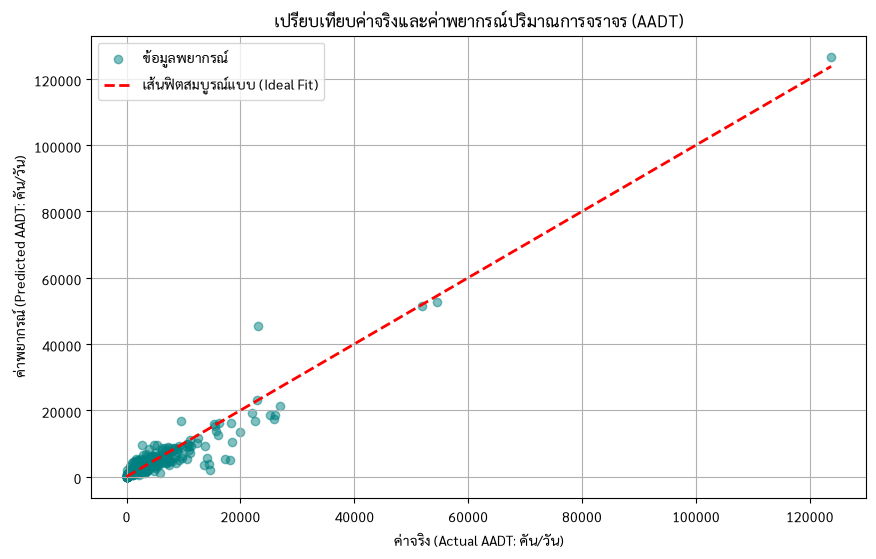

In [18]:
import os
import urllib.request
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. ดาวน์โหลดฟอนต์ภาษาไทยผ่าน Python (รองรับ Windows และ Colab)
font_url = (
    'https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Regular.ttf'
)
font_file = 'Sarabun-Regular.ttf'

if not os.path.exists(font_file):
    urllib.request.urlretrieve(font_url, font_file)

# 2. ตั้งค่าฟอนต์สำหรับ Matplotlib
fm.fontManager.addfont(font_file)
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False

# 3. จัดทำ DataFrame แสดงผลลัพธ์
df_res = pd.DataFrame({
    'Link_ID': X_test['link_id'],
    'Actual_AADT': y_test,
    'Predicted_AADT': y_pred,
    'Error': y_pred - y_test,
    'Abs_Error': np.abs(y_pred - y_test),
})

print('ตัวอย่างผลการทำนาย 10 รายการแรก:')
display(df_res.head(10))

# 4. วาด กราฟเปรียบเทียบ
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='teal', label='ข้อมูลพยากรณ์')
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='เส้นฟิตสมบูรณ์แบบ (Ideal Fit)',
)
plt.xlabel('ค่าจริง (Actual AADT: คัน/วัน)')
plt.ylabel('ค่าพยากรณ์ (Predicted AADT: คัน/วัน)')
plt.title('เปรียบเทียบค่าจริงและค่าพยากรณ์ปริมาณการจราจร (AADT)')
plt.legend()
plt.grid(True)
plt.show()

## 9. บันทึกแบบจำลองเพื่อการใช้งาน (Model Deployment)

In [21]:
# บันทึกโมเดลลงไฟล์ .pkl
model = joblib.load('models/traffic_volume_rf_model.pkl')
joblib.dump(model, 'models/traffic_volume_rf_model.pkl')
print(f"บันทึกโมเดลลงไฟล์ models/traffic_volume_rf_model.pkl เรียบร้อยแล้ว พร้อมนำไปพัฒนาระบบต่อ")

บันทึกโมเดลลงไฟล์ models/traffic_volume_rf_model.pkl เรียบร้อยแล้ว พร้อมนำไปพัฒนาระบบต่อ
